# D4 corrections with MCAMS (and pycorrect for comparison)

Synthetic example: **Ni powder in a vanadium container, inside a furnace**, measured on D4 at
λ = 0.5 Å. The five regrouped measurements (output of `d4creg`), each in `.adat` (2θ, I, σ) and
`.qdat` (Q, I, σ), are in `data/`:

| file | measurement | configuration |
|---|---|---|
| `I_E` | empty environment (furnace) | `h` |
| `I_CE` | empty container in environment | `ch` |
| `I_SCE` | sample in container in environment | `sch` |
| `I_VE` | vanadium rod in environment | `vh` |
| `I_ACE` | ¹⁰B powder (black absorber) in container in environment | `ach` |

Bodies: `s` sample, `c` container, `h` environment (furnace, the "E" of the file names),
`v` vanadium, `a` absorber. A configuration lists the bodies in the beam, from the inside out.

The experiment is described in `Ni_powder.par`. The data were made by `make_synthetic_data.py`
(which also wrote the true values, `data/truth_*.dat`).

**What this notebook does**
1. reads the data (angle or Q scale);
2. computes with **MCAMS** all the Paalman & Pings factors $A_{b,C}$ of the five measured
   configurations, the multiple-scattering ratios $\delta_C$ and the transmissions $T_C$;
3. solves the Paalman & Pings equations **step by step** for the room background $B$, the
   environment $I_E$, the container $I_C$, the vanadium $I_V$ and the sample $I_S$, then
   $d\sigma/d\Omega$ and $S(Q)$; checks against `run_correction` (one line) and the truth;
4. saves everything on the **Q and angle** scales (`results/`);
5. compares with **pycorrect** (CORRECT 2.24) and with the simpler "environment as background"
   treatment.

## Which attenuation factors?

In the Paalman & Pings formalism a factor $A_{b,C}$ is needed for **every body $b$ of every
configuration $C$ that was measured**: it is the attenuation of the scattering of body $b$ when
all the bodies of $C$ are in the beam. Here the measured configurations are E, CE, SCE, VE and
ACE, so the factors are

| measurement | factors |
|---|---|
| `I_E` (h) | $A_{E,E}$ |
| `I_CE` (ch) | $A_{E,CE}$, $A_{C,CE}$ |
| `I_SCE` (sch) | $A_{E,SCE}$, $A_{C,SCE}$, $A_{S,SCE}$ |
| `I_VE` (vh) | $A_{E,VE}$, $A_{V,VE}$ |
| `I_ACE` (ach) | $A_{E,ACE}$, $A_{C,ACE}$, $A_{A,ACE}$ |

(In the code E is written `h`: $A_{S,SCE}$ is `A_s,sch`, $A_{E,CE}$ is `A_h,ch`, ...).

A factor such as $A_{S,S}$, $A_{S,SC}$ or $A_{C,C}$ belongs to a configuration that was **not**
measured here (sample alone, sample in can without furnace, can alone): it does not appear in the
equations. $A_{S,SC}$, $A_{C,SC}$, $A_{C,C}$ are the right ones only if the furnace is not part
of the set-up, i.e. if it is treated as a background (ToScaNA's `environment="background"`,
section 6), which neglects the attenuation of the sample and container scattering by the
furnace and the shadow of the sample on the furnace.

In [1]:
import contextlib, io, math, os, time
import numpy as np
import matplotlib.pyplot as plt

import toscana_path          # this ToScaNA as `toscana` (before any toscana import)
from toscana.dataio.running_params import getRunningParams
from toscana.experiment.measurement import Measurement
from toscana.workflows.correction import read_regrouped, run_correction, structure_factor, save_structure_factor
from toscana.corrections.setup import setups_from_measurement, absorber_setup_from_measurement
from toscana.corrections.factors import compute_factors
from toscana.corrections.pycorrect.correct_2axis import placzek
from toscana.isotopes import Element

INPUT = "adat"               # "adat" (2theta) or "qdat" (Q): both give the same result
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)
%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})

## 1. The experiment and the data

Ni_powder: lambda = 0.5 A, 1069 points, input scale: angle
sample: {'Ni': 1.0}, effective density 0.04572 at/A^3 (packing 0.500)


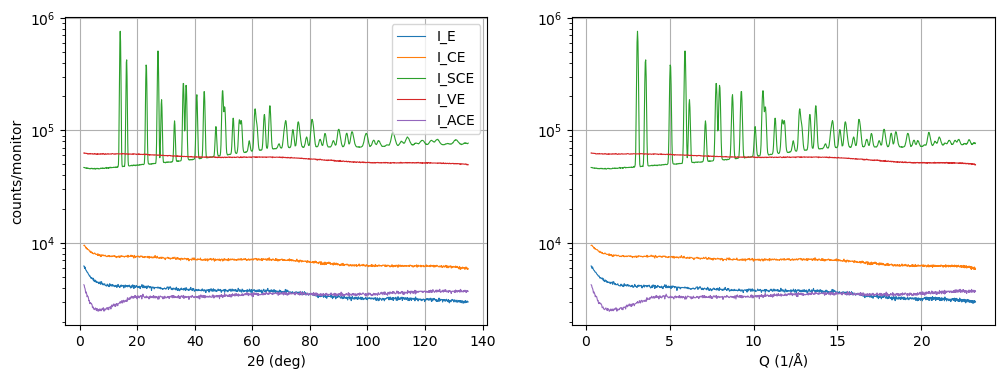

In [2]:
with contextlib.redirect_stdout(io.StringIO()):          # Measurement prints a summary
    m = Measurement(getRunningParams("Ni_powder.par"))
lam = m.wavelength
names = {"environment": "I_E", "container": "I_CE", "sample": "I_SCE",
         "vanadium": "I_VE", "absorber": "I_ACE"}
files = {k: f"data/{n}.{INPUT}" for k, n in names.items()}

data = {}
for key, path in files.items():
    theta, y, e, scale = read_regrouped(path, lam)     # Q is converted to 2theta
    data[key] = (theta, y, e)
theta = data["sample"][0]
q = 4 * math.pi / lam * np.sin(np.radians(theta) / 2)
print(f"{m.Title}: lambda = {lam} A, {len(theta)} points, input scale: {scale}")
print(f"sample: {m.conc}, effective density {m.EffAtomicDensity:.5f} at/A^3 (packing {m.PackingFraction:.3f})")

fig, ax = plt.subplots(1, 2)
for key, n in names.items():
    ax[0].plot(theta, data[key][1], lw=0.8, label=n)
    ax[1].plot(q, data[key][1], lw=0.8, label=n)
ax[0].set(xlabel="2θ (deg)", ylabel="counts/monitor", yscale="log")
ax[1].set(xlabel="Q (1/Å)", yscale="log"); ax[0].legend(); plt.show()

## 2. Set-ups and factors (MCAMS)

Three set-ups of concentric cylinders, built from the `.par` file (`<Sshape>`, `<Cshape>`,
`<Eshape>`, `<Nshape>`, `<Ashape>`, and optional `<LayNN>` lines for more walls or shields):
sample + container + furnace; vanadium + furnace; absorber + container + furnace.
`compute_factors` gives for each configuration $C$ and body $b$: $A_{b,C}(2\theta)$ (MCAMS direct
integration), $\delta_C(2\theta)$ (multiple / single scattering, MCAMS Monte Carlo, isotropic
scatterers), $T_C$ (exact transmission), $n\langle L\rangle_b$ (atoms per beam area) and
$P_b=\sum\rho\sigma_s\langle L\rangle$ (scattering power). About one minute (the furnace is
large).

In [3]:
sample_setup, vanadium_setup = setups_from_measurement(m, environment="layer", vanadium_in_environment=True)
absorber_setup = absorber_setup_from_measurement(m, environment="layer")
for setup, label in ((sample_setup, "sample"), (vanadium_setup, "vanadium"), (absorber_setup, "absorber")):
    print(f"{label} set-up:")
    for l in setup.layers:
        print(f"   {l.name:12s} body {l.body}: d = {l.inner_diam}-{l.outer_diam} mm, h = {l.height} mm, "
              f"mu = {l.mu(lam):.4f} 1/mm, scattering fraction {l.scatter_fraction(lam):.4f}")

t0 = time.time()
fs = compute_factors(sample_setup, theta)                                  # h, ch, sch
fv = compute_factors(vanadium_setup, theta, configurations=["vh"])         # (h already in fs)
fa = compute_factors(absorber_setup, theta, configurations=["ach"])
print(f"\nfactors computed in {time.time() - t0:.0f} s")
i60 = np.argmin(abs(theta - 60))
for f in (fs, fv, fa):
    for key in sorted(f.A):
        print(f"   {key:8s} = {f.A[key][i60]:.4f}  (2theta = 60 deg)")
print("delta  :", {k: round(float(v[i60]), 4) for f in (fs, fv, fa) for k, v in f.delta.items()})
print("T      :", {k: round(v, 4) for f in (fs, fv, fa) for k, v in f.T.items()})
print("P_b    :", {k: round(v, 5) for f in (fs, fv, fa) for k, v in f.scattering_power.items()})

sample set-up:
   sample       body s: d = 0.0-5.0 mm, h = 60.0 mm, mu = 0.0903 1/mm, scattering fraction 0.9368
   container    body c: d = 5.0-5.2 mm, h = 60.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832
   environment  body h: d = 40.0-40.2 mm, h = 100.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832
vanadium set-up:
   vanadium     body v: d = 0.0-6.08 mm, h = 60.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832
   environment  body h: d = 40.0-40.2 mm, h = 100.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832
absorber set-up:
   absorber     body a: d = 0.0-5.0 mm, h = 60.0 mm, mu = 8.0412 1/mm, scattering fraction 0.0029
   container    body c: d = 5.0-5.2 mm, h = 60.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832
   environment  body h: d = 40.0-40.2 mm, h = 100.0 mm, mu = 0.0471 1/mm, scattering fraction 0.7832



factors computed in 85 s
   A_c,ch   = 0.9706  (2theta = 60 deg)
   A_c,sch  = 0.7503  (2theta = 60 deg)
   A_h,ch   = 0.9808  (2theta = 60 deg)
   A_h,h    = 0.9855  (2theta = 60 deg)
   A_h,sch  = 0.8917  (2theta = 60 deg)
   A_s,sch  = 0.6727  (2theta = 60 deg)
   A_h,vh   = 0.9108  (2theta = 60 deg)
   A_v,vh   = 0.7794  (2theta = 60 deg)
   A_a,ach  = 0.0031  (2theta = 60 deg)
   A_c,ach  = 0.2213  (2theta = 60 deg)
   A_h,ach  = 0.6782  (2theta = 60 deg)
delta  : {'delta_h': 0.0125, 'delta_ch': 0.0139, 'delta_sch': 0.2468, 'delta_vh': 0.1272, 'delta_ach': 0.0137}
T      : {'T_h': 0.9906, 'T_ch': 0.9813, 'T_sch': 0.8009, 'T_vh': 0.8403, 'T_ach': 0.3707}
P_b    : {'h': 0.07424, 'c': 0.07384, 's': 2.07611, 'v': 1.33812, 'a': 0.58012}


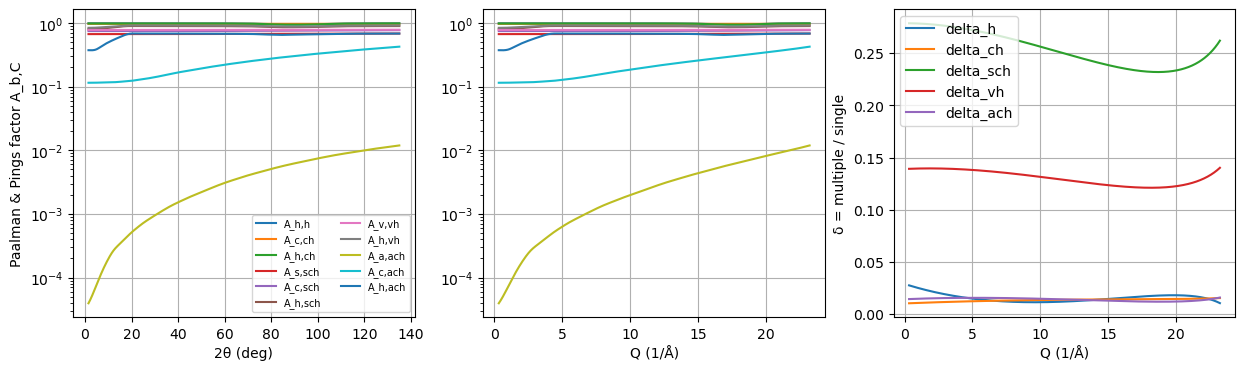

['A_c,ch', 'A_c,ch_err', 'A_c,sch', 'A_c,sch_err', 'A_h,ch', 'A_h,ch_err', 'A_h,h', 'A_h,h_err', 'A_h,sch', 'A_h,sch_err', 'A_s,sch', 'A_s,sch_err', 'delta_ch', 'delta_ch_err', 'delta_h', 'delta_h_err', 'delta_sch', 'delta_sch_err']


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for f in (fs, fv, fa):
    for key, a in f.A.items():
        ax[0].plot(theta, a, label=key)
        ax[1].plot(q, a, label=key)
    for key, d in f.delta.items():
        ax[2].plot(q, d, label=key)
ax[0].set(xlabel="2θ (deg)", ylabel="Paalman & Pings factor A_b,C", yscale="log"); ax[0].legend(fontsize=7, ncol=2)
ax[1].set(xlabel="Q (1/Å)", yscale="log"); ax[2].set(xlabel="Q (1/Å)", ylabel="δ = multiple / single"); ax[2].legend()
plt.show()

for scale in ("q", "angle"):                       # factor files on both scales
    for f, tag in ((fs, "sample"), (fv, "vanadium"), (fa, "absorber")):
        f.save(f"{RESULTS}/Ni_powder_{tag}_factors_{scale}.dat", scale=scale, heading=[f"{tag} set-up"])
x, table = fs.table("q")                            # the same as arrays: x = Q, table["A_s,sch"], ...
print(sorted(table))

## 3. The Paalman & Pings equations, step by step

Every measurement contains the room background $B$ (not attenuated by the set-up), the single
scattering of each body attenuated by its factor, and the multiple scattering
$MS_C = \delta_C\,K\sum_{b\in C}A_{b,C}P_b/4\pi$ ($\delta$ refers to isotropic scatterers, as in
CORRECT):

$$
\begin{aligned}
I_E &= B + A_{E,E}\,I^{1}_E + MS_E\\
I_{CE} &= B + A_{E,CE}\,I^{1}_E + A_{C,CE}\,I^{1}_C + MS_{CE}\\
I_{ACE} &= B + A_{E,ACE}\,I^{1}_E + A_{C,ACE}\,I^{1}_C + A_{A,ACE}\,K P_A/4\pi + MS_{ACE}\\
I_{VE} &= B + A_{E,VE}\,I^{1}_E + A_{V,VE}\,K(1-P^{Pl}_V)P_V/4\pi + MS_{VE}\\
I_{SCE} &= B + A_{E,SCE}\,I^{1}_E + A_{C,SCE}\,I^{1}_C + A_{S,SCE}\,I^{1}_S + MS_{SCE}
\end{aligned}
$$

$I^1_b$: single scattering of body $b$ (before attenuation); $K(2\theta)$: count rate per unit
isotropic cross section (flux × efficiency), so that the vanadium gives
$I^1_V = K P_V/4\pi$ (after the Placzek correction $P^{Pl}_V$) and the absorber, an isotropic
scatterer of known cross section, $K P_A/4\pi$.

The first four equations (no sample) are **linear in four unknowns per angle**:
$B$, $I^1_E$, $I^1_C$, $K$. The absorber measurement is what fixes the room background $B$;
the vanadium fixes $K$. Then the last equation gives $I^1_S$:
$$
I^1_S = \frac{I_{SCE} - B - A_{E,SCE}I^1_E - A_{C,SCE}I^1_C - MS_{SCE}}{A_{S,SCE}},
\qquad \frac{d\sigma}{d\Omega} = \frac{I^1_S}{K\,n\langle L\rangle_S} + \sum_i c_i\frac{\sigma_i}{4\pi}P^{Pl}_i .
$$
Once $B$ and $K$ are known this is the familiar nested Paalman & Pings subtraction (checked
below). Errors: first order, from all five measurements, with correlations.

In [5]:
four_pi = 4 * math.pi
M = {k: data[k][1] for k in data}
E = {k: data[k][2] for k in data}
P = {**fs.scattering_power, **fv.scattering_power, **fa.scattering_power}
P_v_pl = placzek(theta, lam, Element("V").weight, 300.0, "D4", "SERIES_EXPANSION", 0.0)

def ms_coef(f, cfg):           # MS_C / K
    return f.delta[f"delta_{cfg}"] * sum(f.A[f"A_{b},{cfg}"] * P[b] for b in cfg) / four_pi

# rows: E, CE, ACE, VE ; columns: B, I_E, I_C, K
n = len(theta)
A = np.zeros((n, 4, 4))
A[:, :, 0] = 1
A[:, 0, 1] = fs.A["A_h,h"];                               A[:, 0, 3] = ms_coef(fs, "h")
A[:, 1, 1] = fs.A["A_h,ch"];  A[:, 1, 2] = fs.A["A_c,ch"];  A[:, 1, 3] = ms_coef(fs, "ch")
A[:, 2, 1] = fa.A["A_h,ach"]; A[:, 2, 2] = fa.A["A_c,ach"]
A[:, 2, 3] = fa.A["A_a,ach"] * P["a"] / four_pi + ms_coef(fa, "ach")
A[:, 3, 1] = fv.A["A_h,vh"]
A[:, 3, 3] = fv.A["A_v,vh"] * (1 - P_v_pl) * P["v"] / four_pi + ms_coef(fv, "vh")
rhs = np.stack([M["environment"], M["container"], M["absorber"], M["vanadium"]], axis=1)
sig = np.stack([E["environment"], E["container"], E["absorber"], E["vanadium"]], axis=1)

G = np.linalg.inv(A)                                  # x = G · measurements, at each angle
B, I_E, I_C, K = np.einsum("nij,nj->ni", G, rhs).T
I_V = K * P["v"] / four_pi                            # vanadium single scattering (after Placzek)

# sample
MS_sce = K * ms_coef(fs, "sch")
I_S = (M["sample"] - B - fs.A["A_h,sch"] * I_E - fs.A["A_c,sch"] * I_C - MS_sce) / fs.A["A_s,sch"]
Ni = Element("Ni")
P_s_pl = placzek(theta, lam, Ni.weight, m.TempK, "D4", "SERIES_EXPANSION", 0.0)
nL_s = fs.atoms_per_area["s"]
dcs = I_S / (K * nL_s) + Ni.sig_sca / four_pi * P_s_pl

# errors: derivatives with respect to the five measurements
r = np.stack([np.ones(n), fs.A["A_h,sch"], fs.A["A_c,sch"], ms_coef(fs, "sch")], axis=1)
dIs = -np.einsum("ni,nij->nj", r, G) / fs.A["A_s,sch"][:, None]       # d I_S / d (E, CE, ACE, VE)
ddcs = dIs / (K * nL_s)[:, None] - (I_S / (K**2 * nL_s))[:, None] * G[:, 3, :]
dcs_err = np.sqrt((E["sample"] / (fs.A["A_s,sch"] * K * nL_s))**2 + np.sum((ddcs * sig)**2, axis=1))

# the same as the classical nested subtraction, once B and K are known
I_E_nested = (M["environment"] - B - K * ms_coef(fs, "h")) / fs.A["A_h,h"]
I_C_nested = (M["container"] - B - K * ms_coef(fs, "ch") - fs.A["A_h,ch"] * I_E_nested) / fs.A["A_c,ch"]
print("nested vs system: I_E", np.abs(I_E_nested / I_E - 1).max(), " I_C", np.abs(I_C_nested / I_C - 1).max())
print(f"dsigma/dOmega at high Q: {dcs[q > 20].mean():.4f} barn/sr  (sigma_s/4pi = {Ni.sig_sca / four_pi:.4f})")

nested vs system: I_E 1.2212453270876722e-15  I_C 9.992007221626409e-16
dsigma/dOmega at high Q: 1.4700 barn/sr  (sigma_s/4pi = 1.4722)


## 4. The same in one line, and comparison with the truth

`run_correction(m, environment="layer", vanadium_in_environment=True)` builds and solves the
same system (`absorber_model="configuration"` is chosen automatically when the environment is a
body and an absorber is given; with more measurements than unknowns, e.g. an extra
empty-instrument run, it uses weighted least squares).

["absorber measurement used as configuration 'ach': B, I_h, I_c and K solved together at each angle"]
step by step vs run_correction: max |diff| dsigma/dOmega = 7.105427357601002e-15
                                max |diff| errors        = 6.938893903907228e-17
                                max rel. diff of B, I_E   = 2.7588376028120365e-11 1.4210854715202004e-14
vs truth: mean (dcs - true)/sigma = -0.046, rms = 0.998  (noise only: 0 and ~1)


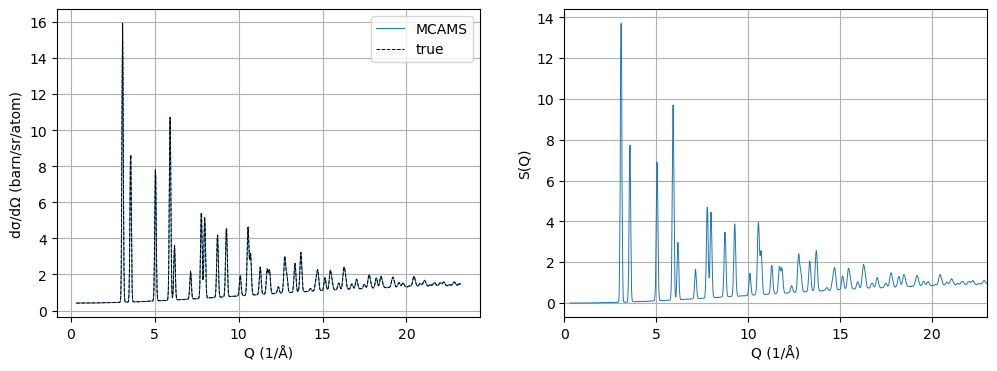

In [6]:
res = run_correction(m, files=files, environment="layer", vanadium_in_environment=True)
print(res.notes)
print("step by step vs run_correction: max |diff| dsigma/dOmega =", np.abs(res.dcs - dcs).max())
print("                                max |diff| errors        =", np.abs(res.err - dcs_err).max())
print("                                max rel. diff of B, I_E   =",
      np.abs(res.backgrounds["B"] / B - 1).max(), np.abs(res.intensities["I_h"] / I_E - 1).max())

truth = np.loadtxt(f"data/truth_{'angle' if INPUT == 'adat' else 'q'}.dat")   # S dcs I_s I_c I_h I_v K B
z = (res.dcs - truth[:, 2]) / res.err
print(f"vs truth: mean (dcs - true)/sigma = {z.mean():+.3f}, rms = {z.std():.3f}  (noise only: 0 and ~1)")

sq = structure_factor(res, m, q_grid=m.qScale)
fig, ax = plt.subplots(1, 2)
ax[0].plot(res.q, res.dcs, lw=0.7, label="MCAMS")
ax[0].plot(res.q, truth[:, 2], "k--", lw=0.7, label="true")
ax[0].set(xlabel="Q (1/Å)", ylabel="dσ/dΩ (barn/sr/atom)"); ax[0].legend()
ax[1].plot(sq[:, 0], sq[:, 1], lw=0.7); ax[1].set(xlabel="Q (1/Å)", ylabel="S(Q)", xlim=(0, 23))
plt.show()

## 5. $I_S$, $I_V$ and the other contributions on the Q and angle scales, files

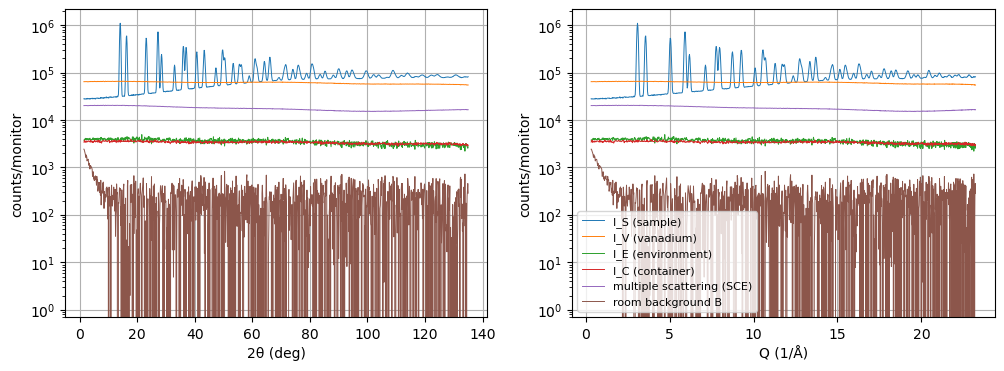

Ni_powder_absorber_factors_angle.dat
Ni_powder_absorber_factors_q.dat
Ni_powder_mcams.soq
Ni_powder_mcams_dcs.dat
Ni_powder_mcams_intensities_angle.dat
Ni_powder_mcams_intensities_q.dat
Ni_powder_sample_factors_angle.dat
Ni_powder_sample_factors_q.dat
Ni_powder_vanadium_factors_angle.dat
Ni_powder_vanadium_factors_q.dat


In [7]:
fig, ax = plt.subplots(1, 2)
for i, (x, lab) in enumerate(((res.theta, "2θ (deg)"), (res.q, "Q (1/Å)"))):
    ax[i].plot(x, res.intensities["I_s"], lw=0.7, label="I_S (sample)")
    ax[i].plot(x, res.intensities["I_v"], lw=0.7, label="I_V (vanadium)")
    ax[i].plot(x, res.intensities["I_h"], lw=0.7, label="I_E (environment)")
    ax[i].plot(x, res.intensities["I_c"], lw=0.7, label="I_C (container)")
    ax[i].plot(x, res.intensities["MS_sch"], lw=0.7, label="multiple scattering (SCE)")
    ax[i].plot(x, res.backgrounds["B"], lw=0.7, label="room background B")
    ax[i].set(xlabel=lab, ylabel="counts/monitor", yscale="log")
ax[1].legend(fontsize=8); plt.show()

for scale in ("q", "angle"):
    res.save_intensities(f"{RESULTS}/Ni_powder_mcams_intensities_{scale}.dat", scale=scale)
# (the factor files were written in section 2; res.save_factors(basename, scale) does the same)
np.savetxt(f"{RESULTS}/Ni_powder_mcams_dcs.dat", np.column_stack([res.theta, res.q, res.dcs, res.err]),
           fmt="%14.7g", header="2theta(deg) Q(1/A) dsigma/dOmega(barn/sr/atom) error")
save_structure_factor(f"{RESULTS}/Ni_powder_mcams.soq", sq, ["Ni powder, MCAMS"])
print("\n".join(sorted(os.listdir(RESULTS))))

## 6. Comparisons: environment as background, and pycorrect

* **Environment as background** (`environment="background"`): the furnace is not a body; the
  empty-furnace measurement is subtracted with the absorber formula
  $B_C = T_C I_E + (1-T_C) I_{ACE}$ and only $A_{S,SC}$, $A_{C,SC}$, $A_{C,C}$, $A_{V,V}$ are
  used. It neglects the attenuation of the sample and container scattering by the furnace and the
  details of the shadow of the sample on it.
* **pycorrect** (CORRECT 2.24) with the furnace as a body (`furnace`, `vanadium /furnace`): it
  computes $A_{S,SCE}$, $A_{C,SCE}$, $A_{E,SCE}$, $A_{C,CE}$, $A_{E,CE}$, $A_{E,E}$ itself, but it
  cannot treat the absorber measurement as a configuration: the best it can do is to subtract it
  as a background from every measurement.

factor    MCAMS/pycorrect at 2theta = 20, 60, 120 deg
A_s,sch   0.6696/0.6697  0.6727/0.6728  0.6808/0.6812
A_c,sch   0.7463/0.7459  0.7503/0.7500  0.7668/0.7674
A_h,sch   0.8962/0.8214  0.8917/0.8486  0.8926/0.8592
A_c,ch    0.9706/0.9707  0.9706/0.9706  0.9706/0.9707
A_h,ch    0.9856/0.9660  0.9808/0.9470  0.9809/0.9474
A_h,h     0.9903/0.9734  0.9855/0.9520  0.9855/0.9520
A_v,vh    0.7780/0.7781  0.7794/0.7795  0.7831/0.7834
A_h,vh    0.9152/0.8535  0.9108/0.8707  0.9116/0.8762


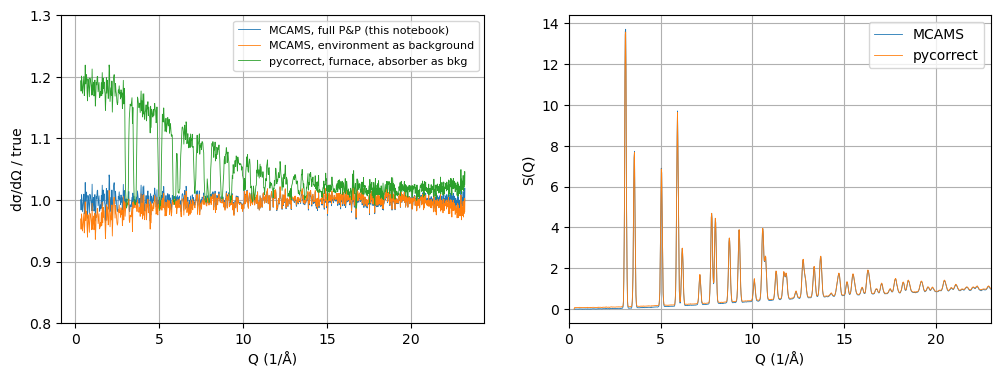

environment as background : dsigma/dOmega / true from 0.936 to 1.028 (median 0.996)
pycorrect                 : dsigma/dOmega / true from 0.983 to 1.219 (median 1.025)


In [8]:
RUN_COMPARISONS = True
if RUN_COMPARISONS:
    files_bkg = dict(files, empty=files["environment"])
    res_bkg = run_correction(m, files=files_bkg, environment="background")
    pyc = run_correction(m, method="pycorrect", environment="furnace", vanadium_in_environment=True,
                         files=dict(files, background=files["absorber"]), workdir=f"{RESULTS}/pycorrect_work")

    print(f"{'factor':9s} MCAMS/pycorrect at 2theta = 20, 60, 120 deg")
    idx = [np.argmin(abs(theta - t)) for t in (20, 60, 120)]
    for key in ("A_s,sch", "A_c,sch", "A_h,sch", "A_c,ch", "A_h,ch", "A_h,h"):
        print(f"{key:9s} " + "  ".join(f"{res.factors.A[key][i]:.4f}/{pyc.factors.A[key][i]:.4f}" for i in idx))
    for key in ("A_v,vh", "A_h,vh"):
        print(f"{key:9s} " + "  ".join(f"{res.vanadium_factors.A[key][i]:.4f}/{pyc.vanadium_factors.A[key][i]:.4f}" for i in idx))

    fig, ax = plt.subplots(1, 2)
    ax[0].plot(res.q, res.dcs / truth[:, 2], lw=0.6, label="MCAMS, full P&P (this notebook)")
    ax[0].plot(res_bkg.q, res_bkg.dcs / truth[:, 2], lw=0.6, label="MCAMS, environment as background")
    ax[0].plot(pyc.q, pyc.dcs / truth[:, 2], lw=0.6, label="pycorrect, furnace, absorber as bkg")
    ax[0].set(xlabel="Q (1/Å)", ylabel="dσ/dΩ / true", ylim=(0.8, 1.3)); ax[0].legend(fontsize=8)
    sq_p = structure_factor(pyc, m, q_grid=m.qScale)
    ax[1].plot(sq[:, 0], sq[:, 1], lw=0.6, label="MCAMS")
    ax[1].plot(sq_p[:, 0], sq_p[:, 1], lw=0.6, label="pycorrect")
    ax[1].set(xlabel="Q (1/Å)", ylabel="S(Q)", xlim=(0, 23)); ax[1].legend(); plt.show()
    for name, r_ in (("environment as background", res_bkg), ("pycorrect", pyc)):
        rat = r_.dcs / truth[:, 2]
        print(f"{name:26s}: dsigma/dOmega / true from {rat.min():.3f} to {rat.max():.3f} (median {np.median(rat):.3f})")

    for scale in ("q", "angle"):
        pyc.save_factors(f"{RESULTS}/Ni_powder_pycorrect_{scale}", scale=scale)
    save_structure_factor(f"{RESULTS}/Ni_powder_pycorrect.soq", sq_p, ["Ni powder, pycorrect"])

**Reading the comparison.** The synthetic data follow the full Paalman & Pings model with MCAMS
factors, so the full treatment recovers them by construction; the comparison shows the *size* of
the approximations for this set-up:
- the attenuation factors of MCAMS and CORRECT agree within 0.1 % for sample, container and
  vanadium; CORRECT's furnace factors ($A_{E,\cdot}$) are 2–8 % lower. A brute-force integration
  for the thin furnace shell (0.1 mm of V, 8 mm beam) gives $A_{E,E}$ = 0.990, 0.985, 0.986 at
  20°, 60°, 120°, as MCAMS: CORRECT's furnace treatment is not adequate for a beam much narrower
  than the furnace (see also `docs/validation`);
- treating the furnace as a background ignores its attenuation of the sample scattering and the
  exact shadowing, and the absorber formula with $T_C$ only approximates the room background;
- pycorrect also differs through the multiple scattering (one constant δ for the sample only,
  with an empirical series for the higher orders) and because it cannot use the absorber as a
  configuration. Which is closer to reality was studied in `docs/validation`: MCAMS agrees with
  brute-force Monte Carlo.

## 7. The same without the notebook

See `README.md` in this folder. In short, from the `example` folder:

```bash
# ToScaNA command line (MCAMS by default)
python correct.py Ni_powder.par --environment layer --vanadium-in-environment --input qdat --outdir results/cli
# the same with pycorrect (furnace as a body, absorber subtracted as background)
python correct.py Ni_powder.par --method pycorrect --environment layer --vanadium-in-environment \
                  --background data/I_ACE.adat --outdir results/cli_pycorrect

# CORRECT's own command language (pycorrect), from the data folder
cd data && python ../run_pycorrect.py Ni_powder.com

# Python script doing what this notebook does
python run_example.py --input qdat --compare
```